# 1. Seleção, caracterização e preparação dos dados

Notebook da seção 3.1 do projeto: identifica os arquivos e metadados do DronePropB, seleciona os registros comparáveis, verifica se podem ser analisados e organiza os sinais em janelas.

## 1.1 Configuração

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.io_utils import (DATA_DIR, get_info_name, get_data, get_rotulo, get_id,
                          carregar, ler_acc, estat, std_por_bloco, fundamental, digest)

ARQUIVOS = sorted(DATA_DIR.glob("*.mat"))
ARQ = {"saudavel": "F0_SV0_SP1_C1_R1.mat", "defeituoso": "F1_SV3_SP1_C1.mat"}
CORES = {"saudavel": "tab:blue", "defeituoso": "tab:red"}
print(len(ARQUIVOS))

111


## 1.2 Leitura dos arquivos e metadados (requisito 3.1.1)

Para cada arquivo, `get_data` lê `AccData` e `IMUData` e registra a fs calculada pelo vetor de tempo e a declarada (`samplingRate`), o número de amostras, a irregularidade do passo de tempo e os NaN. Os códigos `F`, `SV`, `SP`, `C` e `R` vêm do nome do arquivo.

In [2]:
linhas = []
for arquivo in ARQUIVOS:
    info = get_data(arquivo.name)
    info["arquivo"] = arquivo.name
    linhas.append(info)
df = pd.DataFrame(linhas)

## 1.3 Conferência dos nomes, cópias e durações

- Confere se os códigos lidos do nome batem com os de `get_info_name`.
- Calcula um hash de cada sinal para encontrar arquivos com conteúdo idêntico.
- Resume quantos registros existem por condição, quais sensores estão presentes, os valores de fs e as durações.

In [3]:
assert df["arquivo"].notna().all() and df["arquivo"].is_unique
info = pd.DataFrame(df["arquivo"].apply(get_info_name).tolist())
for col in ["F", "SV", "SP", "C"]:
    assert (info[col] == df[col]).all(), f"divergência em {col}"
assert (info["R"].fillna(-1) == df["R"].fillna(-1)).all()
print("nomes OK:", len(df), "registros")


df["hash_acc"] = df["acc"].apply(digest)
df["hash_imu"] = df["imu"].apply(digest)

for h in ["hash_acc", "hash_imu"]:
    dup = df[df[h].notna() & df.duplicated(h, keep=False)].copy()
    dup["grupo"] = dup.groupby(h).ngroup()
    print(f"\n{h}: {len(dup)} arquivos em {dup['grupo'].nunique()} grupos duplicados")
    print(dup.sort_values("grupo")[["grupo", "arquivo"]].to_string(index=False))

df["dur_acc"] = df["n_acc_sig"] / df["fs_acc"]
df["dur_imu"] = df["n_imu_sig"] / df["fs_imu"]

print("\nRegistros por F e SP:")
print(df.groupby(["F", "SP"]).size())
print("\nSensores presentes por F, SP e C:")
print(df.groupby(["F", "SP", "C"])[["tem_imu", "tem_acc"]].sum())
print("\nValores distintos de fs:")
print(df[["fs_acc", "fs_imu", "fs_acc_decl", "fs_imu_decl"]].round(3).nunique())
print("\nDurações (s):")
print(df[["dur_acc", "dur_imu"]].describe())

df = df.drop(columns=["imu", "acc"])
Path("../results/tables").mkdir(parents=True, exist_ok=True)
df.to_csv("../results/tables/registros.csv", index=False)

nomes OK: 111 registros



hash_acc: 18 arquivos em 9 grupos duplicados
 grupo              arquivo
     0 F0_SV0_SP3_C1_R1.mat
     0 F0_SV0_SP3_C2_R1.mat
     1 F0_SV0_SP3_C1_R2.mat
     1 F0_SV0_SP3_C2_R2.mat
     2 F0_SV0_SP1_C2_R3.mat
     2 F0_SV0_SP1_C1_R3.mat
     3 F0_SV0_SP2_C1_R1.mat
     3 F0_SV0_SP2_C2_R1.mat
     4 F0_SV0_SP2_C2_R3.mat
     4 F0_SV0_SP2_C1_R3.mat
     5 F0_SV0_SP2_C2_R2.mat
     5 F0_SV0_SP2_C1_R2.mat
     6 F0_SV0_SP3_C2_R3.mat
     6 F0_SV0_SP3_C1_R3.mat
     7 F0_SV0_SP1_C2_R2.mat
     7 F0_SV0_SP1_C1_R2.mat
     8 F0_SV0_SP1_C2_R1.mat
     8 F0_SV0_SP1_C1_R1.mat

hash_imu: 18 arquivos em 9 grupos duplicados
 grupo              arquivo
     0 F0_SV0_SP1_C1_R1.mat
     0 F0_SV0_SP1_C2_R1.mat
     1 F0_SV0_SP1_C1_R2.mat
     1 F0_SV0_SP1_C2_R2.mat
     2 F0_SV0_SP3_C1_R3.mat
     2 F0_SV0_SP3_C2_R3.mat
     3 F0_SV0_SP3_C2_R1.mat
     3 F0_SV0_SP3_C1_R1.mat
     4 F0_SV0_SP2_C2_R3.mat
     4 F0_SV0_SP2_C1_R3.mat
     5 F0_SV0_SP2_C1_R1.mat
     5 F0_SV0_SP2_C2_R1.mat
     6 F0_SV

### O que se vê

- **111 arquivos**, todos com nome no padrão `F#_SV#_SP#_C#[_R#]`. Os códigos lidos conferem com `get_info_name`.
- **9 pares de arquivos com o `AccData` idêntico (mesmo hash), todos saudáveis.** Em cada par, o `C2_Rk` é igual ao `C1_Rk` do mesmo `SP`. A IMU também é idêntica nos mesmos pares. Então são arquivos duplicados, e não gravações diferentes.
- **Cada combinação de `F` e `SP` tem 9 registros**: 3 `C` × 3 repetições nos saudáveis, e 3 `C` × 3 severidades nos defeituosos. Há mais 3 saudáveis em `SP0`.
- **`AccData`:** uma única taxa, fs = 10 kHz, igual à declarada em todos os arquivos.
- **IMU:** a taxa declarada é 1000 Hz, mas a calculada pelo vetor de tempo tem 5 valores diferentes (alguns registros ficam ligeiramente abaixo de 1000 Hz). A IMU não existe nos 3 arquivos de `SP0` (`C4`).
- **Durações do `AccData`:** 20 s (todos os `C3` defeituosos e os saudáveis `C3_R1`), 60 s (os demais) e 120 s (`SP0`). A IMU tem durações diferentes (de 32 a 95 s), então os dois sensores não cobrem o mesmo intervalo.

## 1.4 Rótulo e identificação do registro

- `rotulo` / `y`: `F0` é saudável (`y = 0`) e `F1` a `F3` são defeituosos (`y = 1`). A classe positiva é a defeituosa.
- `id`: o mesmo número para sinais idênticos (mesmo hash). Ele é usado na divisão treino/teste, para que cópias não fiquem dos dois lados.

In [4]:
get_id(df)
get_rotulo(df)

In [5]:
df.columns

Index(['tem_imu', 'tem_acc', 'fs_imu', 'fs_imu_decl', 'fs_acc', 'fs_acc_decl',
       'n_imu_t', 'n_imu_sig', 'n_acc_t', 'n_acc_sig', 'dt_std_imu',
       'dt_std_acc', 'nan_imu', 'nan_acc', 'F', 'SV', 'SP', 'C', 'R',
       'arquivo', 'hash_acc', 'hash_imu', 'dur_acc', 'dur_imu', 'id', 'copias',
       'rotulo', 'y'],
      dtype='object')

## 1.5 Seleção dos registros

São usados os registros com `SP > 0` e sem cópia (`copias == False`). A justificativa está na seção 1.6.

In [6]:
sel = (df['SP'] > 0) & (df['copias'] == False)
sel = df[sel]

In [7]:
Path("../results/tables").mkdir(parents=True, exist_ok=True)
df.to_csv("../results/tables/registros.csv", index=False)
sel.to_csv("../results/tables/registros_selecionados.csv", index=False)

In [8]:
sel[sel["dur_acc"] < 60][["arquivo", "dur_acc", "dur_imu"]].to_string()

'                  arquivo  dur_acc  dur_imu\n9    F0_SV0_SP1_C3_R1.mat     20.0   35.213\n18   F0_SV0_SP2_C3_R1.mat     20.0   34.620\n27   F0_SV0_SP3_C3_R1.mat     20.0   32.413\n32      F1_SV1_SP1_C3.mat     20.0   35.201\n35      F1_SV1_SP2_C3.mat     20.0   32.502\n38      F1_SV1_SP3_C3.mat     20.0   32.307\n41      F1_SV2_SP1_C3.mat     20.0   31.955\n44      F1_SV2_SP2_C3.mat     20.0   31.916\n47      F1_SV2_SP3_C3.mat     20.0   32.532\n50      F1_SV3_SP1_C3.mat     20.0   32.725\n53      F1_SV3_SP2_C3.mat     20.0   32.992\n56      F1_SV3_SP3_C3.mat     20.0   31.918\n59      F2_SV1_SP1_C3.mat     20.0   38.133\n62      F2_SV1_SP2_C3.mat     20.0   32.140\n65      F2_SV1_SP3_C3.mat     20.0   31.918\n68      F2_SV2_SP1_C3.mat     20.0   33.388\n71      F2_SV2_SP2_C3.mat     20.0   32.987\n74      F2_SV2_SP3_C3.mat     20.0   32.536\n77      F2_SV3_SP1_C3.mat     20.0   32.820\n80      F2_SV3_SP2_C3.mat     20.0   32.524\n83      F2_SV3_SP3_C3.mat     20.0   32.352\n86      F

In [9]:
sel.head(10)

,tem_imu,tem_acc,fs_imu,fs_imu_decl,fs_acc,fs_acc_decl,n_imu_t,n_imu_sig,n_acc_t,n_acc_sig,...,R,arquivo,hash_acc,hash_imu,dur_acc,dur_imu,id,copias,rotulo,y
3,True,True,1000.0,1000.0,10000.0,10000,82344.0,82344.0,600000,600000,...,1.0,F0_SV0_SP1_C1_R1.mat,cd83ca6b352637c6f8be693bf1539369,1052b24d08d16d04e8489d631e7be8f4,60.0,82.344,3,False,saudavel,0
4,True,True,1000.0,1000.0,10000.0,10000,94846.0,94846.0,600000,600000,...,2.0,F0_SV0_SP1_C1_R2.mat,af6e6a123e21232dd6f82c0b1820761b,13f90e005fb2228592abb2a0d376b626,60.0,94.846,4,False,saudavel,0
5,True,True,1000.0,1000.0,10000.0,10000,86121.0,86121.0,600000,600000,...,3.0,F0_SV0_SP1_C1_R3.mat,5e1acdeedbb18efd7a07ca510e5da299,e99384c8e32a364843bf56541785acdf,60.0,86.121,5,False,saudavel,0
9,True,True,1000.0,1000.0,10000.0,10000,35213.0,35213.0,200000,200000,...,1.0,F0_SV0_SP1_C3_R1.mat,703ad5375b2fe4097712464016dd4daf,203a4f029613b626117fc0cf2312391e,20.0,35.213,6,False,saudavel,0
10,True,True,1000.0,1000.0,10000.0,10000,84992.0,84992.0,600000,600000,...,2.0,F0_SV0_SP1_C3_R2.mat,c455f1b4f9e97fc5c38a6a698c17f2d4,4c1162dfcdd23c22e06e22cef268ef70,60.0,84.992,7,False,saudavel,0
11,True,True,1000.0,1000.0,10000.0,10000,86036.0,86036.0,600000,600000,...,3.0,F0_SV0_SP1_C3_R3.mat,c830339ac2473e8897cab8075f40f1a2,323a8401d702eaa2c50193d1f3138c1b,60.0,86.036,8,False,saudavel,0
12,True,True,1000.0,1000.0,10000.0,10000,81119.0,81119.0,600000,600000,...,1.0,F0_SV0_SP2_C1_R1.mat,73952abe012b045c18ad6085cfad9911,e3958fc50be32f7990fc5da67057fd7b,60.0,81.119,9,False,saudavel,0
13,True,True,1000.0,1000.0,10000.0,10000,80965.0,80965.0,600000,600000,...,2.0,F0_SV0_SP2_C1_R2.mat,90b9b14d483a341955462ad025f43d7d,f528c9e011fb4c2f7d2a8e1208048cab,60.0,80.965,10,False,saudavel,0
14,True,True,1000.0,1000.0,10000.0,10000,83196.0,83196.0,600000,600000,...,3.0,F0_SV0_SP2_C1_R3.mat,75d47d14a698e035c4a9b4ac265ce98d,d80681af3a6f9867b016e4a06999d2ea,60.0,83.196,11,False,saudavel,0
18,True,True,1000.0,1000.0,10000.0,10000,34620.0,34620.0,200000,200000,...,1.0,F0_SV0_SP2_C3_R1.mat,43f431c60ace068f3928a959a91d9117,f030b5657142b26766fc2e0c603b8a5e,20.0,34.620,12,False,saudavel,0


## 1.6 Registros escolhidos, rótulos e justificativa da comparação (requisito 3.1.2)

Duas tabelas:

1. **Um registro por linha** (`results/tables/registros_selecionados_resumo.csv`): os 99 registros usados, com rótulo (`y = 1` defeituosa), tipo de falha, severidade, `SP`, `C`, repetição, fs, duração e número de janelas de 2 s.
2. **Um grupo de comparação por linha** (`results/tables/grupos_comparacao.csv`): quantos saudáveis e defeituosos existem em cada combinação de `SP` e `C`, e o que foi excluído e por quê.

Os nomes dos tipos de falha (`F1` corte na borda, `F2` trinca, `F3` corte na superfície) seguem a convenção do dataset irmão DronePropA (Ismail et al., 2025). Eles não estão confirmados na documentação do DronePropB.

In [10]:
# Tabela 1: um registro por linha (os 99 usados)
N = 20000  # janela de 2 s a 10 kHz (mesmo valor do janelamento abaixo)
TIPO = {0: "saudável", 1: "corte na borda", 2: "trinca", 3: "corte na superfície"}  # convenção do DronePropA

tab_reg = sel[["arquivo", "id", "rotulo", "y", "F", "SV", "SP", "C", "R", "fs_acc", "n_acc_sig", "dur_acc"]].copy()
tab_reg.insert(5, "tipo_falha", tab_reg["F"].map(TIPO))
tab_reg["n_jan"] = (tab_reg["n_acc_sig"] // N).astype(int)
tab_reg["R"] = tab_reg["R"].astype("Int64")
tab_reg.to_csv("../results/tables/registros_selecionados_resumo.csv", index=False)
print(f"{len(tab_reg)} registros usados:", tab_reg["rotulo"].value_counts().to_dict())
display(tab_reg.head(12))

# Tabela 2: um grupo de comparação (SP, C) por linha, incluindo o que foi excluído
def motivo(g):
    if (g["SP"] == 0).all():
        return "excluído: SP0 só tem saudáveis"
    if g["copias"].all():
        return "excluído: cópias idênticas dos C1"
    return "usado"

linhas = []
for (sp, c), g in df.groupby(["SP", "C"]):
    for rot, gg in g.groupby("rotulo"):
        linhas.append({"SP": sp, "C": c, "rotulo": rot, "n_reg": len(gg),
                       "dur_s": "/".join(str(int(d)) for d in sorted(gg["dur_acc"].unique())),
                       "situacao": motivo(gg)})
grupos = pd.DataFrame(linhas)

usados = grupos[grupos["situacao"] == "usado"]
piv = usados.pivot_table(index=["SP", "C"], columns="rotulo", values="n_reg", fill_value=0)
dur = usados.pivot_table(index=["SP", "C"], columns="rotulo", values="dur_s", aggfunc="first")
resumo = pd.DataFrame({
    "saudáveis": piv.get("saudavel", 0).astype(int),
    "defeituosos": piv.get("defeituoso", 0).astype(int),
    "dur. saudável (s)": dur.get("saudavel"),
    "dur. defeituoso (s)": dur.get("defeituoso"),
}).reset_index()
resumo["comparação"] = np.where(resumo["saudáveis"] > 0,
                                "saudável × defeituoso no mesmo SP e C",
                                "sem saudável próprio: comparar com C1 do mesmo SP")
resumo = resumo.fillna("—")
resumo.to_csv("../results/tables/grupos_comparacao.csv", index=False)

print("\nGrupos usados (SP, C):")
print(resumo.to_string(index=False))
print("\nExcluídos:")
print(grupos[grupos["situacao"] != "usado"].to_string(index=False))

99 registros usados: {'defeituoso': 81, 'saudavel': 18}


,arquivo,id,rotulo,y,F,tipo_falha,SV,SP,C,R,fs_acc,n_acc_sig,dur_acc,n_jan
3,F0_SV0_SP1_C1_R1.mat,3,saudavel,0,0,saudável,0,1,1,1,10000.0,600000,60.0,30
4,F0_SV0_SP1_C1_R2.mat,4,saudavel,0,0,saudável,0,1,1,2,10000.0,600000,60.0,30
5,F0_SV0_SP1_C1_R3.mat,5,saudavel,0,0,saudável,0,1,1,3,10000.0,600000,60.0,30
9,F0_SV0_SP1_C3_R1.mat,6,saudavel,0,0,saudável,0,1,3,1,10000.0,200000,20.0,10
10,F0_SV0_SP1_C3_R2.mat,7,saudavel,0,0,saudável,0,1,3,2,10000.0,600000,60.0,30
11,F0_SV0_SP1_C3_R3.mat,8,saudavel,0,0,saudável,0,1,3,3,10000.0,600000,60.0,30
12,F0_SV0_SP2_C1_R1.mat,9,saudavel,0,0,saudável,0,2,1,1,10000.0,600000,60.0,30
13,F0_SV0_SP2_C1_R2.mat,10,saudavel,0,0,saudável,0,2,1,2,10000.0,600000,60.0,30
14,F0_SV0_SP2_C1_R3.mat,11,saudavel,0,0,saudável,0,2,1,3,10000.0,600000,60.0,30
18,F0_SV0_SP2_C3_R1.mat,12,saudavel,0,0,saudável,0,2,3,1,10000.0,200000,20.0,10



Grupos usados (SP, C):
 SP  C  saudáveis  defeituosos dur. saudável (s) dur. defeituoso (s)                                        comparação
  1  1          3            9                60                  60             saudável × defeituoso no mesmo SP e C
  1  2          0            9                 —                  60 sem saudável próprio: comparar com C1 do mesmo SP
  1  3          3            9             20/60                  20             saudável × defeituoso no mesmo SP e C
  2  1          3            9                60                  60             saudável × defeituoso no mesmo SP e C
  2  2          0            9                 —                  60 sem saudável próprio: comparar com C1 do mesmo SP
  2  3          3            9             20/60                  20             saudável × defeituoso no mesmo SP e C
  3  1          3            9                60                  60             saudável × defeituoso no mesmo SP e C
  3  2          0       

### Justificativa da comparação

Uma diferença entre saudável e defeituosa só pode ser atribuída à hélice se as outras condições forem iguais. Por isso, as comparações são feitas **dentro do mesmo grupo de `SP` e `C`**:

- **Mesmo `SP`.** A frequência do pico principal do `AccData` sobe com o `SP` (cerca de 56 Hz em `SP1`, 99 Hz em `SP2` e 133 Hz em `SP3`, notebook 3). Então o `SP` se comporta como nível de rotação. Comparar `SP` diferentes misturaria o efeito da rotação com o do defeito.
- **Mesmo `C`.** O significado de `C` não está documentado. Mantê-lo fixo evita que uma condição desconhecida entre como diferença entre as classes.
- **Mesmo sensor e mesma taxa.** Todos usam `AccData` com fs = 10 kHz, conferida em todos os 111 registros.
- **Mesmo janelamento.** Janelas de 2 s (N = 20000, Δf = 0,5 Hz) em todos os registros. A duração total varia: no `C3`, os defeituosos têm 20 s e os saudáveis têm 20 s (`R1`) ou 60 s (`R2`, `R3`). Isso muda o número de janelas por registro, mas não as características de cada janela.

Cada grupo de `SP` e `C` usado tem 3 saudáveis (`R1` a `R3`) e 9 defeituosos (3 tipos × 3 severidades, sem repetição).

**Exclusões:**
- `SP0` (`F0_SV0_SP0_C4_R1` a `R3`): só existe para saudáveis, então não há defeituoso para comparar.
- Saudáveis `C2` (9 arquivos): o sinal é idêntico ao do `C1` de mesmo `SP` e `R` (mesmo hash). Mantê-los contaria o mesmo sinal duas vezes e poderia colocar cópias em treino e teste. Por isso, os defeituosos `C2` não têm saudável próprio e só são comparados com os saudáveis `C1` do mesmo `SP`. Essa comparação assume que `C` não altera o sinal saudável, o que não dá para verificar.

## 1.7 Inspeção visual dos sinais e escolha do sensor (requisito 3.1.3)

Compara o par ilustrativo saudável × defeituoso (mesmo `SP` e `C`) no `AccData` e nos três canais da IMU. Isso serve para escolher o sensor usado na análise e para ver trechos de partida e parada, offsets e valores fora do esperado.

                      mean     std     min      max  pct_no_max  pct_no_min
canal   cond                                                               
imu_ch1 defeituoso  0.0194  0.5824 -2.4229   2.0159      0.0012      0.0012
        saudavel    0.0310  0.6789 -2.7007   2.7773      0.0012      0.0012
imu_ch2 defeituoso -0.2067  0.6055 -2.5283   2.3463      0.0012      0.0012
        saudavel   -0.2014  0.8118 -3.2561   2.7773      0.0012      0.0012
imu_ch3 defeituoso  9.7227  0.9346  5.0230  13.9055      0.0012      0.0012
        saudavel    9.7175  1.0897  4.9560  13.9438      0.0012      0.0012
piezo   defeituoso -0.0010  0.0312 -0.1535   0.1795      0.0003      0.0002
        saudavel   -0.0010  0.0444 -0.2703   0.3087      0.0002      0.0002


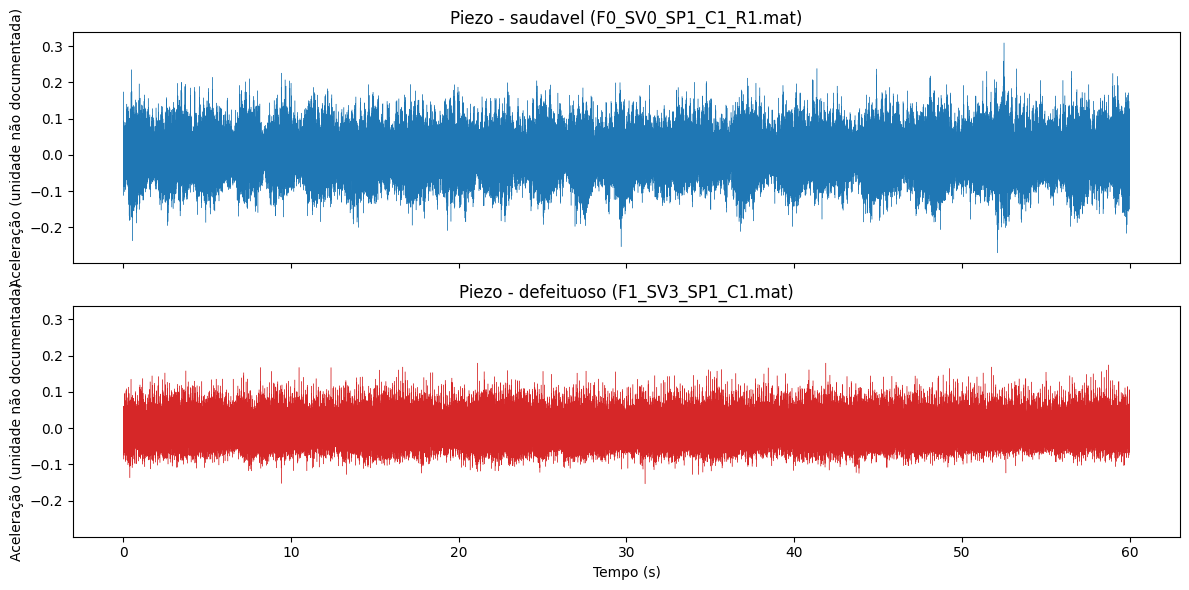

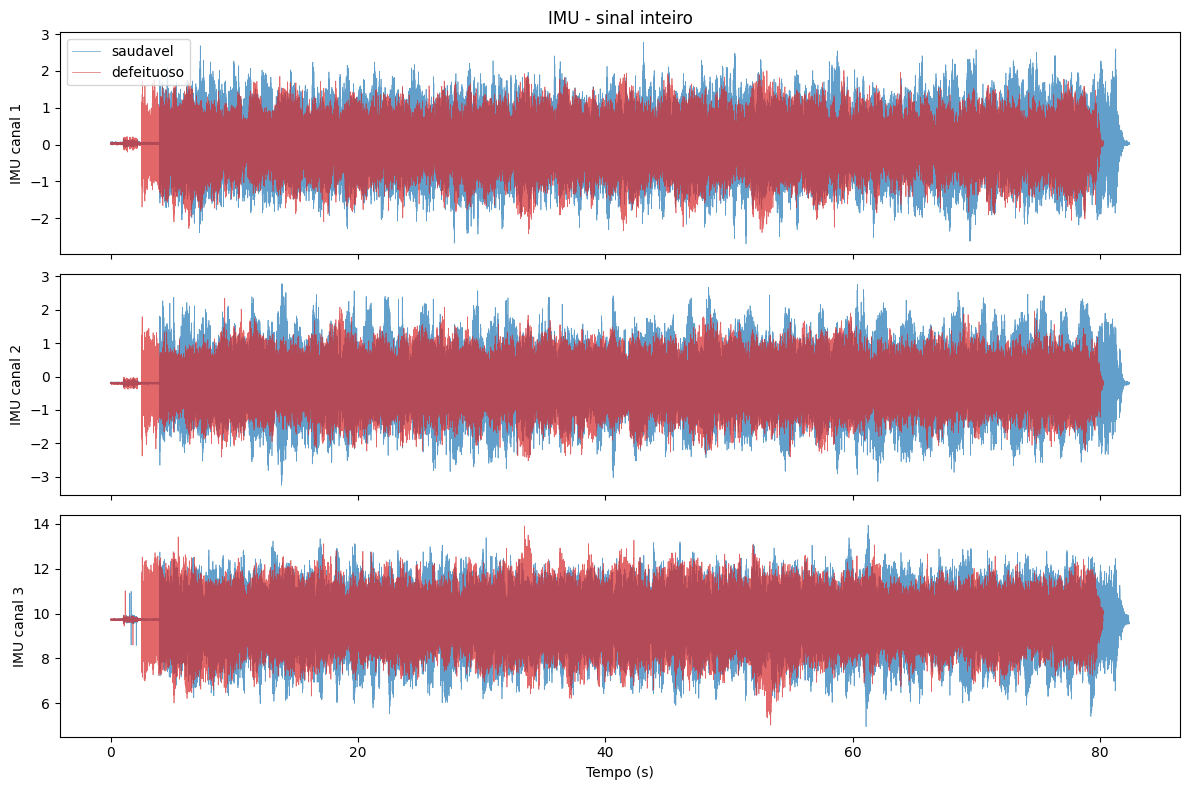

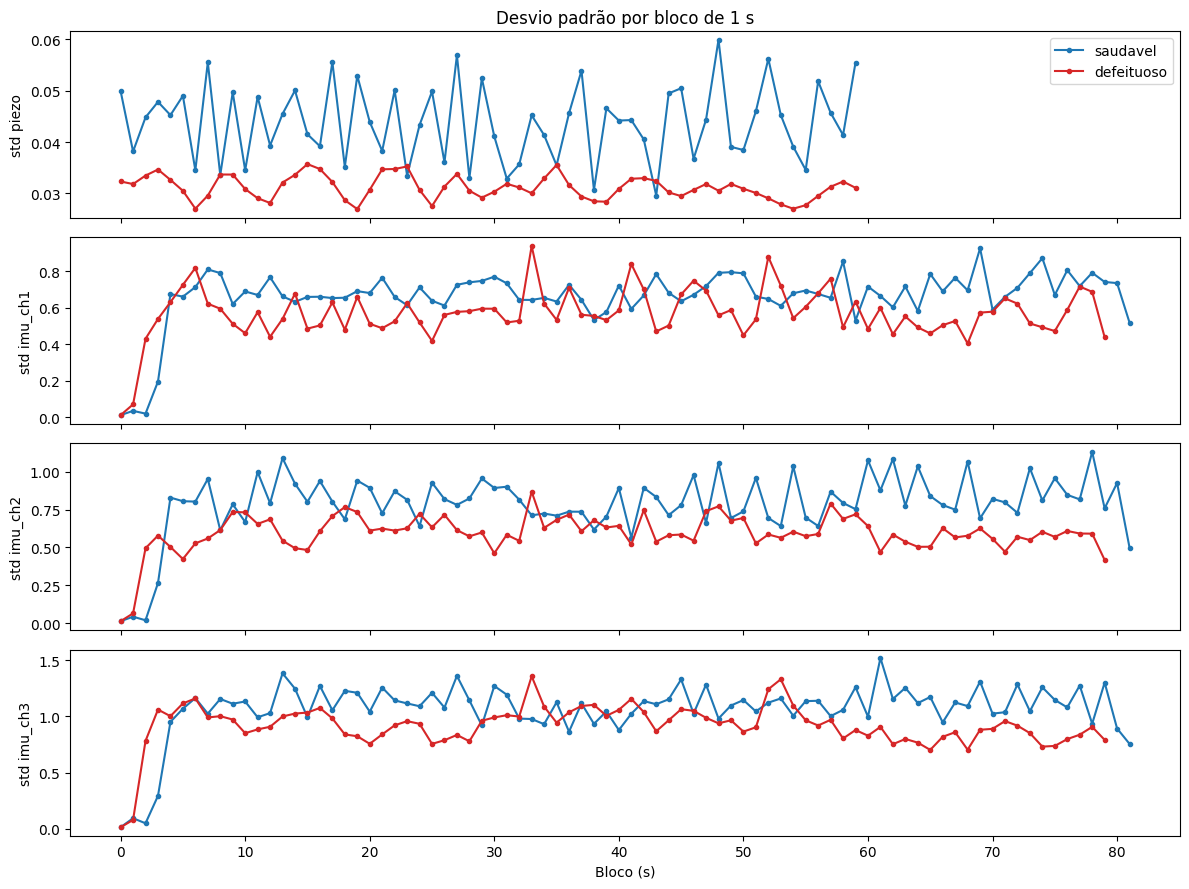

In [11]:
sinais = {cond: carregar(nome) for cond, nome in ARQ.items()}

linhas = []
for cond, (imu_s, acc_s) in sinais.items():
    for i in range(imu_s.Vib_Data.shape[0]):
        linhas.append({"cond": cond, "canal": f"imu_ch{i + 1}", **estat(imu_s.Vib_Data[i])})
    linhas.append({"cond": cond, "canal": "piezo", **estat(acc_s.Vib_Data)})

tab = pd.DataFrame(linhas).set_index(["canal", "cond"]).sort_index()
print(tab.round(4).to_string())

fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, (cond, (imu_s, acc_s)) in zip(axs, sinais.items()):
    ax.plot(acc_s.t, acc_s.Vib_Data, lw=0.3, color=CORES[cond])
    ax.set_title(f"Piezo - {cond} ({ARQ[cond]})")
    ax.set_ylabel("Aceleração (unidade não documentada)")
axs[-1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for i, ax in enumerate(axs):
    for cond, (imu_s, acc_s) in sinais.items():
        ax.plot(imu_s.t, imu_s.Vib_Data[i], lw=0.5, color=CORES[cond], alpha=0.7, label=cond)
    ax.set_ylabel(f"IMU canal {i + 1}")
axs[0].legend()
axs[0].set_title("IMU - sinal inteiro")
axs[-1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

series = [("piezo", lambda s: s[1].t, lambda s: s[1].Vib_Data)]
for i in range(3):
    series.append((f"imu_ch{i + 1}", lambda s: s[0].t, lambda s, i=i: s[0].Vib_Data[i]))

fig, axs = plt.subplots(len(series), 1, figsize=(12, 9), sharex=True)
for ax, (nome, get_t, get_x) in zip(axs, series):
    for cond, s in sinais.items():
        ax.plot(std_por_bloco(get_t(s), get_x(s)), color=CORES[cond], marker=".", label=cond)
    ax.set_ylabel(f"std {nome}")
axs[0].legend()
axs[0].set_title("Desvio padrão por bloco de 1 s")
axs[-1].set_xlabel("Bloco (s)")
plt.tight_layout()
plt.show()

### Escolha do sensor

- **`AccData`:** a média é ≈ −0,001 e o desvio padrão fica entre 0,03 e 0,05. O desvio por bloco de 1 s é estável do primeiro ao último bloco, então o registro não tem trecho de partida ou parada.
- **IMU:**
  - nos primeiros 2 a 4 s, o sinal fica quase parado (desvio ≈ 0) e depois sobe em rampa, o que indica a partida do motor. No saudável, os últimos ≈ 2 s mostram a parada. Esses trechos teriam que ser recortados;
  - o canal 3 tem um offset de ≈ 9,72, compatível com a gravidade (≈ 9,8 m/s², se a unidade for m/s², o que não está documentado). O canal 2 tem offset de ≈ −0,2;
  - com fs = 1 kHz, o Nyquist é 500 Hz, contra 5 kHz no `AccData`.
- **Decisão:** a análise usa só o `AccData`. Ele é estável, não tem offset relevante, tem 10 vezes mais banda e existe em todos os registros. Sua unidade não está documentada, então os valores aparecem em unidades arbitrárias (u.a.). Ele provavelmente é o acelerômetro piezoelétrico descrito no dataset, mas isso não está confirmado nos arquivos.

## 1.8 Verificação dos registros selecionados (requisito 3.1.3)

Para cada registro usado, verifica no `AccData`:
- **NaN:** amostras inválidas.
- **Saturação:** fração de amostras no máximo e no mínimo. Muitas amostras no mesmo extremo indicariam corte pelo conversor.
- **Estabilidade:** razão entre o maior e o menor desvio padrão por janela de 2 s. Uma razão alta indicaria partida, parada ou trecho anômalo que precisaria ser recortado (limiar adotado: 3).

In [12]:
N = 20000
chk = []
for _, r in sel.iterrows():
    x = ler_acc(r["arquivo"])
    k = len(x) // N
    s = x[:k * N].reshape(k, N).std(axis=1)
    chk.append({
        "arquivo": r["arquivo"], "nan": int(np.isnan(x).sum()),
        "pct_max": 100 * np.mean(x == x.max()), "pct_min": 100 * np.mean(x == x.min()),
        "std_min": s.min(), "std_max": s.max(), "n_jan": k,
    })
chk = pd.DataFrame(chk)
chk["razao"] = chk["std_max"] / chk["std_min"]
print(chk[["nan", "pct_max", "pct_min", "razao", "n_jan"]].describe().round(4).to_string())
print(chk.sort_values("razao", ascending=False).head(10).to_string(index=False))

        nan  pct_max  pct_min    razao    n_jan
count  99.0  99.0000  99.0000  99.0000  99.0000
mean    0.0   0.0003   0.0003   1.3271  23.9394
std     0.0   0.0002   0.0002   0.2035   9.2381
min     0.0   0.0002   0.0002   1.0275  10.0000
25%     0.0   0.0002   0.0002   1.1530  10.0000
50%     0.0   0.0002   0.0002   1.3105  30.0000
75%     0.0   0.0005   0.0005   1.4889  30.0000
max     0.0   0.0010   0.0010   1.9496  30.0000
             arquivo  nan  pct_max  pct_min  std_min  std_max  n_jan    razao
   F1_SV1_SP1_C2.mat    0 0.000167 0.000167 0.032521 0.063402     30 1.949603
   F3_SV3_SP2_C2.mat    0 0.000167 0.000167 0.074287 0.139003     30 1.871164
F0_SV0_SP1_C3_R2.mat    0 0.000167 0.000167 0.013694 0.023628     30 1.725432
   F3_SV2_SP1_C2.mat    0 0.000167 0.000167 0.024316 0.041079     30 1.689368
   F3_SV2_SP1_C1.mat    0 0.000167 0.000167 0.023049 0.038240     30 1.659049
   F3_SV1_SP2_C2.mat    0 0.000167 0.000167 0.073855 0.122203     30 1.654639
   F3_SV2_SP3_C2.mat  

### O que se vê

- **NaN:** nenhum nos 99 registros.
- **Saturação:** o valor máximo e o mínimo aparecem em no máximo 0,001% das amostras, ou seja, 1 ou 2 amostras por registro. Se o conversor cortasse o sinal, muitas amostras ficariam presas no mesmo extremo. Não há sinal disso.
- **Estabilidade:** a razão entre o maior e o menor desvio por janela de 2 s fica entre 1,03 e 1,95 (mediana 1,31), sempre abaixo do limiar de 3. Os maiores valores não vêm de partida ou parada, porque o `AccData` não tem esses trechos (seção 1.7).
- **Decisão:** nenhum recorte foi aplicado, e os 99 registros são usados inteiros.

## 1.9 Janelamento (requisito 3.1.4)

- Janela de **2 s = 20000 amostras** a fs = 10 kHz, sem sobreposição. A resolução espectral é Δf = fs/N = 0,5 Hz.
- O resto no fim do registro (menos de uma janela) é descartado.
- Cada janela guarda `arquivo` e `id` do registro de origem. Só os índices `ini` e `fim` são salvos, e os sinais são relidos do `.mat` nos próximos notebooks.

In [13]:
jan = sel[["arquivo", "id", "rotulo", "F", "SV", "SP", "C"]].copy()
jan["n_jan"] = (sel["n_acc_sig"] // N).astype(int).values
jan = jan.loc[jan.index.repeat(jan["n_jan"])].copy()
jan["jan"] = jan.groupby("arquivo").cumcount()
jan["ini"] = jan["jan"] * N
jan["fim"] = jan["ini"] + N
jan = jan.reset_index(drop=True)
print(len(jan))
print(jan.groupby("rotulo").size())
jan.to_csv("../data/processed/janelas.csv", index=False)

2370
rotulo
defeituoso    1890
saudavel       480
dtype: int64


### Resultado e limitações da preparação

- **2370 janelas: 480 saudáveis (20%) e 1890 defeituosas.** As classes são desbalanceadas, o que pesa na escolha das métricas da classificação (seção 3.5).
- **Número de janelas por registro:** 10 (registros de 20 s) ou 30 (60 s). Nas análises por janela, os registros longos pesam mais. Por isso, os notebooks seguintes também comparam pela mediana de cada registro.
- **Janelas do mesmo registro não são independentes.** A divisão treino/teste terá que ser feita por registro (`id`).

**Limitações declaradas:**

- **Unidade:** a unidade do `AccData` não está documentada. Os valores são tratados como u.a.
- **Códigos do nome do arquivo:** o significado de `F`, `SV`, `SP` e `C` não está documentado no DronePropB.
  - `F` (tipo de falha) e `SV` (severidade) seguem a convenção do dataset irmão DronePropA.
  - `SP` foi inferido dos dados como nível de velocidade: o pico principal sobe de ≈ 56 para ≈ 99 e ≈ 133 Hz de `SP1` a `SP3` (notebooks 3 e 6).
  - `C` tem significado desconhecido e só é usado para formar os grupos de comparação.
- **Data de gravação:** os 81 defeituosos foram gravados em setembro de 2024, e 12 dos 18 saudáveis (`R2` e `R3`) em novembro (`AccData.DATE`). Parte das diferenças entre as condições pode ser efeito da sessão de gravação, e não da hélice. Os notebooks 2 (seção 2.8), 5 (seção 4) e 6 (seção 3) verificam isso.